<a href="https://colab.research.google.com/github/gee666thu/r5-machine-learning-lab/blob/main/modf%209.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [4]:
iris = load_iris()
X = iris.data[:, [2, 3]]
y = (iris.target != 0).astype(int)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Data ready")

Data ready


In [6]:
model = SVC(kernel="linear", C=1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [7]:
print("Accuracy:", round(accuracy_score(y_test, y_pred)*100, 2), "%")

Accuracy: 100.0 %


In [8]:
x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
y_min, y_max = X[:,1].min()-1, X[:,1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

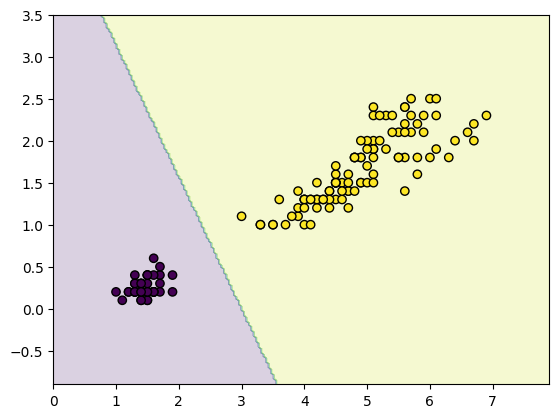

In [9]:
plt.contourf(xx, yy, Z, alpha=0.2)
plt.scatter(X[:,0], X[:,1], c=y, edgecolors='k')
w = model.coef_[0]
b = model.intercept_[0]
x_vals = np.linspace(x_min, x_max, 100)

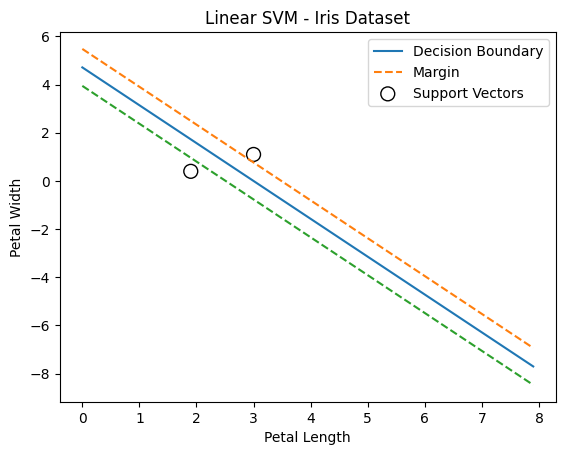

In [10]:
 bd = -(w[0]*x_vals + b) / w[1]
 mg = 1 / np.sqrt(np.sum(w**2))
 plt.plot(x_vals, bd, label="Decision Boundary")
 plt.plot(x_vals, bd+mg, "--", label="Margin")
 plt.plot(x_vals, bd-mg, "--")
 plt.scatter(model.support_vectors_[:,0], model.support_vectors_[:,1], s=100, facecolors='none', edgecolors='k', label="Support Vectors")
 plt.xlabel("Petal Length")
 plt.ylabel("Petal Width")
 plt.title("Linear SVM - Iris Dataset"); plt.legend(); plt.show()